# Explore

In [92]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Create Proxies From Raw Data

Data from https://www.investing.com/commodities/ice-dutch-ttf-gas-c1-futures-historical-data

### Forward curve proxy

The monthly series is used as a proxy for the forward curve because a delivery-month curve is not available. It contains historical prices for a generic ICE Dutch TTF futures series, not prices for multiple delivery months observed on the same date. It therefore does not represent a true forward curve. Results using this proxy are illustrative only.

In [93]:
monthly = pd.read_csv("../data/raw/ICE Dutch TTF Natural Gas Futures Historical Data Monthly.csv")
monthly.head(2)

,Date,Price,Open,High,Low,Vol.,Change %
0,10/01/2026,93.853,72.40,94.11,71.050,2.27M,29.71%
1,09/01/2026,72.357,70.16,84.50,67.875,2.94M,3.65%


In [94]:
def create_forward_curve_proxy(monthly: pd.DataFrame) -> pd.DataFrame:
    proxy = monthly[["Date", "Price"]].copy()
    proxy["Date"] = pd.to_datetime(proxy["Date"], format="%m/%d/%Y")
    proxy["Price"] = pd.to_numeric(proxy["Price"], errors="raise")
    proxy = proxy.rename(columns={"Date": "date", "Price": "price_eur_mwh"})

    return proxy.set_index("date").sort_index()


forward_curve_proxy = create_forward_curve_proxy(monthly)
forward_curve_proxy.head(2)

,price_eur_mwh
date,
2010-11-01,21.89
2010-12-01,24.05


### Daily spot price proxy

This daily series contains historical prices for Investing.com's generic front-month ICE Dutch TTF futures contract. It is not a day-ahead spot-price series. As the front-month contract rolls to the next delivery month, observed changes may include roll effects, and futures prices may differ from spot prices. We use the series only to test the simulation workflow; parameter estimates and simulated paths are illustrative, not calibrated to the actual spot market.

In [96]:
daily = pd.read_csv("../data/raw/ICE Dutch TTF Natural Gas Futures Historical Data Daily.csv")
daily.head(2)

,Date,Price,Open,High,Low,Vol.,Change %
0,10/23/2026,93.853,90.400,94.11,90.295,151.29K,4.23%
1,10/22/2026,90.043,87.105,91.47,86.955,126.30K,2.99%


In [101]:
def create_spot_price_proxy(daily: pd.DataFrame) -> pd.DataFrame:
    proxy = daily[["Date", "Price"]].copy()
    proxy["Date"] = pd.to_datetime(proxy["Date"], format="%m/%d/%Y")
    proxy["Price"] = pd.to_numeric(proxy["Price"], errors="raise")
    proxy = proxy.rename(columns={"Date": "date", "Price": "price_eur_mwh"})

    return proxy.set_index("date").sort_index()


spot_price_proxy = create_spot_price_proxy(daily)
spot_price_proxy.head(2)

,price_eur_mwh
date,
2010-03-15,11.60
2010-03-16,11.41


### Plot forward curve and daily spot prices for 2020

Illustrative assumption: To demonstrate the distinction between a forward curve and spot prices, this chart treats the monthly TTF futures series as a forward-curve proxy and the daily series as a spot-price proxy. In reality, both are historical generic front-month futures prices. 

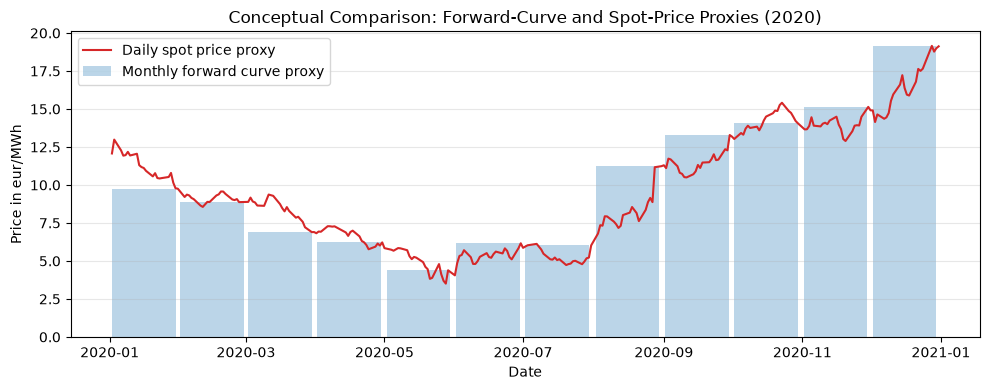

In [102]:
curve_2020 = forward_curve_proxy.loc["2020":"2020", "price_eur_mwh"]
daily_2020 = spot_price_proxy.loc["2020":"2020", "price_eur_mwh"]

month_midpoints = curve_2020.index + pd.to_timedelta(
    (curve_2020.index.days_in_month - 1) / 2,
    unit="D",
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    daily_2020.index,
    daily_2020,
    color = 'tab:red',
    label="Daily spot price proxy",
)
ax.bar(
    month_midpoints,
    curve_2020,
    color="tab:blue",
    width=28,
    alpha=0.3,
    label="Monthly forward curve proxy",
)

ax.set(
    title="Conceptual Comparison: Forward-Curve and Spot-Price Proxies (2020)",
    xlabel="Date",
    ylabel="Price in eur/MWh",
)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

## Calibrate One-Factor Model

In [99]:
spot_prices_2011_2019 = spot_price_proxy["2011":"2019"]
spot_prices_2011_2019

,price_eur_mwh
date,
2011-01-03,24.050
2011-01-04,22.810
2011-01-05,22.500
2011-01-06,22.900
2011-01-07,22.700
...,...
2019-12-23,13.027
2019-12-24,12.607
2019-12-27,12.767


In [100]:
spot = spot_prices_2011_2019["price_eur_mwh"]

x = np.log(spot)
dates = x.index

# Consecutive observations can be more than one calendar day apart.
dt = dates.to_series().diff().dt.days.to_numpy()[1:]
dx = np.diff(x.to_numpy())
x_start = x.to_numpy()[:-1]

# Monthly effects approximate the seasonal level in the historical data.
month_effects = pd.get_dummies(dates.month[:-1], dtype=float).to_numpy()
design = np.column_stack([x_start, month_effects])

# Fit dx/dt = -kappa * x + month-specific intercepts.
sqrt_dt = np.sqrt(dt)
weighted_design = design * sqrt_dt[:, None]
weighted_target = (dx / dt) * sqrt_dt

coefficients = np.linalg.lstsq(
    weighted_design,
    weighted_target,
    rcond=None,
)[0]

kappa = -coefficients[0]
if kappa <= 0:
    raise ValueError(f"Expected positive mean reversion; got kappa={kappa:.6f}")

fitted_rate = design @ coefficients
standardized_residuals = (dx - fitted_rate * dt) / sqrt_dt
sigma = np.sqrt(np.mean(standardized_residuals**2))

print(f"kappa: {kappa:.6f} per day")
print(f"sigma: {sigma:.6f} per sqrt(day)")

kappa: 0.001941 per day
sigma: 0.019731 per sqrt(day)
